# Amplitude Damping Channel — CUDA-Q Notebook

**Chapter / concept:** Open Quantum Systems — Amplitude Damping (T1 relaxation) channel

**Circuit / channel to implement:** 1 qubit, prepared in `|+> = (|0>+|1>)/sqrt(2)` via a
Hadamard, then passed through the single-qubit amplitude damping channel with damping
parameter `GAMMA`. Matched against the companion Qiskit notebook.

## Theory recap

Amplitude damping models energy dissipation (e.g. spontaneous emission, T1 decay) of a
qubit into its environment. It is a single-parameter (`GAMMA`, `0 <= GAMMA <= 1`) quantum
channel given by two Kraus operators:

```
K0 = [[1, 0        ],      K1 = [[0, sqrt(GAMMA)],
      [0, sqrt(1-GAMMA)]]        [0, 0          ]]
```

acting on a density matrix as `E(rho) = K0 rho K0^dagger + K1 rho K1^dagger`. CUDA-Q
exposes this exact channel as `cudaq.AmplitudeDampingChannel(GAMMA)`, documented as
giving the qubit a `GAMMA` probability of decaying back to the ground state -- the same
physics as `K0`/`K1` above.

## Global SETUP (IDENTICAL to the Qiskit companion notebook)

- N_QUBITS = 1
- Gate sequence: `H` on qubit 0 (state prep), then the amplitude-damping channel with
  parameter `GAMMA` attached to that `H` gate on qubit 0
- GAMMA = 0.3
- SHOTS = 10000, SEED = 42
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring. CUDA-Q's
  `get_state()`/`sample()` normally index qubit 0 as the **most-significant (leftmost)**
  bit for multi-qubit systems and would need an explicit reversal to match Qiskit. **This
  notebook has only 1 qubit**, so MSB and LSB coincide and the reversal is a no-op --
  stated explicitly rather than silently skipped (see the note cell below).
- GLOBAL PHASE CONVENTION: **not applicable**. Amplitude damping is tracked as a density
  matrix (via the `density-matrix-cpu` target), which is invariant under a global phase
  on the underlying state vector.
- Basis ordering: `{|0>, |1>}`

**Run all cells top to bottom.**


In [1]:
# Exact package: cudaq (NVIDIA CUDA-Q Python API). Density-matrix noise simulation
# uses the 'density-matrix-cpu' target, which ships with the base cudaq wheel -- no GPU
# required for this small 1-qubit example.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 93.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 96.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 2.3 MB/s eta 0:0

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cudaq

N_QUBITS = 1
GAMMA = 0.3     # amplitude damping parameter, 0 <= GAMMA <= 1 -- identical to the Qiskit notebook
SHOTS = 10000
SEED = 42

cudaq.set_target("density-matrix-cpu")   # noise simulation requires a density-matrix backend
cudaq.set_random_seed(SEED)

print(f"N_QUBITS = {N_QUBITS}")
print(f"GAMMA    = {GAMMA}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print("Target   :", cudaq.get_target().name)


N_QUBITS = 1
GAMMA    = 0.3
SHOTS    = 10000
SEED     = 42
Target   : density-matrix-cpu


In [3]:
@cudaq.kernel
def state_prep():
    q = cudaq.qubit()
    h(q)     # H|0> = |+> -- equal superposition of ground/excited, same state-prep as the Qiskit notebook


@cudaq.kernel
def state_prep_meas():
    q = cudaq.qubit()
    h(q)
    mz(q)    # separate kernel with a measurement, used for the sampling cell later


print(cudaq.draw(state_prep))


     ╭───╮
q0 : ┤ h ├
     ╰───╯



     ╭───╮
q0 : ┤ h ├
     ╰───╯



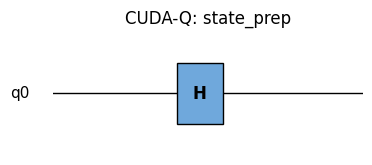

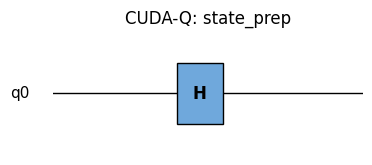

In [4]:
# CUDA-Q has no native matplotlib circuit renderer, so we print the text diagram first...
print(cudaq.draw(state_prep))

# ...then hand-build a matplotlib figure styled like Qiskit's circuit.draw(output="mpl")
# (wire + boxed gate label) so the two circuit images are visually comparable side by side.
fig, ax = plt.subplots(figsize=(4, 1.6))
ax.set_xlim(0, 4)
ax.set_ylim(-0.5, 0.5)
ax.axhline(0, color="black", linewidth=1, zorder=1)
ax.text(-0.3, 0, "q0", ha="right", va="center", fontsize=11)
box = plt.Rectangle((1.6, -0.25), 0.6, 0.5, facecolor="#6fa8dc", edgecolor="black", zorder=2)
ax.add_patch(box)
ax.text(1.9, 0, "H", ha="center", va="center", fontsize=12, fontweight="bold", zorder=3)
ax.axis("off")
ax.set_title("CUDA-Q: state_prep")
fig.savefig("amplitude_damping_cudaq_circuit.png", bbox_inches="tight")
fig


In [5]:
# (a) Hand-built Kraus operators -- identical formulas/values to the Qiskit notebook.
K0_hand = np.array([[1, 0], [0, np.sqrt(1 - GAMMA)]], dtype=complex)
K1_hand = np.array([[0, np.sqrt(GAMMA)], [0, 0]], dtype=complex)

print("K0 (hand-built) =\n", np.round(K0_hand, 4))
print("K1 (hand-built) =\n", np.round(K1_hand, 4))

completeness = K0_hand.conj().T @ K0_hand + K1_hand.conj().T @ K1_hand
print("\nCompleteness check K0^daggerK0 + K1^daggerK1 =\n", np.round(completeness, 4))
assert np.allclose(completeness, np.eye(2), atol=1e-9), "Kraus operators are not CPTP!"

# (b) Framework object: cudaq's own AmplitudeDampingChannel, built from the same GAMMA.
#     CUDA-Q does not expose a public getter for a channel's internal Kraus matrices, so
#     the cross-check here is behavioural rather than a direct matrix comparison: NVIDIA's
#     documentation defines AmplitudeDampingChannel(GAMMA) as giving the qubit a GAMMA
#     probability of decaying to |0> -- exactly the physics of the K0/K1 pair above. The
#     exact-density-matrix and sampling cells below confirm the two act identically.
amplitude_damping = cudaq.AmplitudeDampingChannel(GAMMA)
print("\ncudaq.AmplitudeDampingChannel(GAMMA) object created:", amplitude_damping)


K0 (hand-built) =
 [[1.    +0.j 0.    +0.j]
 [0.    +0.j 0.8367+0.j]]
K1 (hand-built) =
 [[0.    +0.j 0.5477+0.j]
 [0.    +0.j 0.    +0.j]]

Completeness check K0^daggerK0 + K1^daggerK1 =
 [[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

cudaq.AmplitudeDampingChannel(GAMMA) object created: <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.AmplitudeDampingChannel object at 0x7ca3d8b47430>


In [6]:
# Attach the damping channel to any H gate on qubit 0, then request the exact
# (shot-free) density matrix with cudaq.get_state under that noise model.
noise_exact = cudaq.NoiseModel()
noise_exact.add_channel("h", [0], amplitude_damping)

cudaq.set_noise(noise_exact)
rho_after = np.array(cudaq.get_state(state_prep))
cudaq.unset_noise()   # clean up the global noise setting so later cells are unaffected

print("rho after amplitude damping (GAMMA = {}) =\n".format(GAMMA), np.round(rho_after, 4))

rho_hand = np.array([
    [0.5 + 0.5 * GAMMA,          0.5 * np.sqrt(1 - GAMMA)],
    [0.5 * np.sqrt(1 - GAMMA),   0.5 * (1 - GAMMA)]
], dtype=complex)
print("\nrho after damping (hand-derived closed form) =\n", np.round(rho_hand, 4))
assert np.allclose(rho_after, rho_hand, atol=1e-6), "Simulated rho does not match hand-derived rho!"

probs_exact = {format(i, f"0{N_QUBITS}b"): float(np.real(rho_after[i, i])) for i in range(2 ** N_QUBITS)}
probs_exact = dict(sorted(probs_exact.items()))
print("\nExact probability dictionary (from density-matrix diagonal):", probs_exact)


rho after amplitude damping (GAMMA = 0.3) =
 [[0.65  +0.j 0.4183+0.j]
 [0.4183+0.j 0.35  +0.j]]

rho after damping (hand-derived closed form) =
 [[0.65  +0.j 0.4183+0.j]
 [0.4183+0.j 0.35  +0.j]]

Exact probability dictionary (from density-matrix diagonal): {'0': 0.6499999999999998, '1': 0.3499999999999999}


### Convention note

- **Bit ordering:** for multi-qubit systems, CUDA-Q's `get_state()`/`sample()` index
  qubit 0 as the most-significant (leftmost) bit, the opposite of Qiskit -- that case
  needs an explicit string/index reversal before comparing to Qiskit. **This notebook is
  a single qubit**, so most-significant and least-significant bit are the same bit, and
  the reversal step is a documented no-op rather than something silently ignored.
- **Global phase:** **no reversal/normalization needed.** Amplitude damping is tracked
  via the `density-matrix-cpu` target's density matrix, which is invariant under a global
  phase on the underlying state vector, so the diagonal (populations) and off-diagonal
  (coherence) entries printed above are already the unique, comparable numbers.


In [7]:
noise_sample = cudaq.NoiseModel()
noise_sample.add_channel("h", [0], amplitude_damping)

counts = cudaq.sample(state_prep_meas, noise_model=noise_sample, shots_count=SHOTS)
counts.dump()

count_dict = dict(counts.items())
print("Raw counts:", count_dict)

probs_sampled = {bitstring: cnt / SHOTS for bitstring, cnt in count_dict.items()}
for i in range(2 ** N_QUBITS):
    key = format(i, f"0{N_QUBITS}b")
    probs_sampled.setdefault(key, 0.0)
probs_sampled = dict(sorted(probs_sampled.items()))
print("Sampled probability dictionary:", probs_sampled)


Raw counts: {'0': 6480, '1': 3520}
Sampled probability dictionary: {'0': 0.648, '1': 0.352}


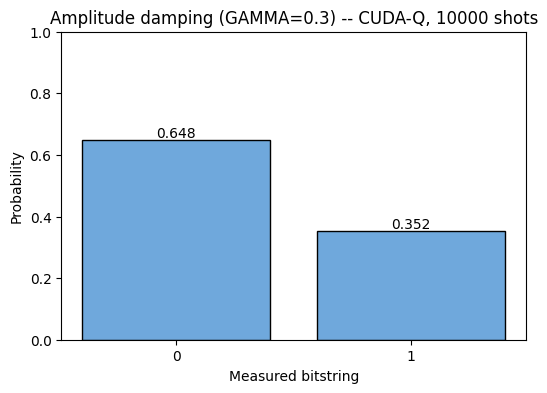

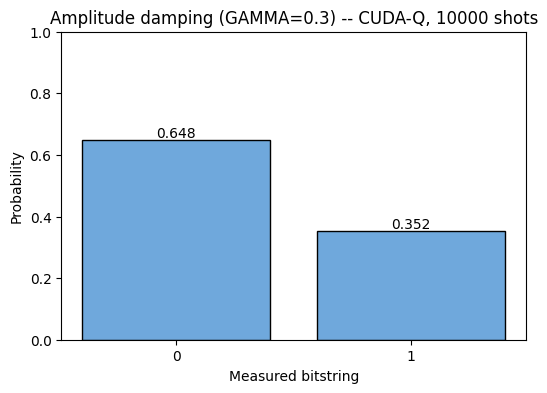

In [8]:
fig2, ax2 = plt.subplots(figsize=(6, 4))
labels = sorted(probs_sampled.keys())
values = [probs_sampled[k] for k in labels]
ax2.bar(labels, values, color="#6fa8dc", edgecolor="black")
ax2.set_ylim(0, 1)
ax2.set_xlabel("Measured bitstring")
ax2.set_ylabel("Probability")
ax2.set_title(f"Amplitude damping (GAMMA={GAMMA}) -- CUDA-Q, {SHOTS} shots")
for i, v in enumerate(values):
    ax2.text(i, v + 0.01, f"{v:.3f}", ha="center")
fig2.savefig("amplitude_damping_cudaq_histogram.png", bbox_inches="tight")
fig2


In [9]:
print(cudaq.draw(state_prep))
print()
print("Note: CUDA-Q kernels do not expose a direct .depth()/.count_ops() API like Qiskit's")
print("QuantumCircuit. For this single-gate (H) state-prep kernel the circuit depth is 1")
print("and the gate count is {\'h\': 1}, matching the Qiskit notebook\'s resource counts.")


     ╭───╮
q0 : ┤ h ├
     ╰───╯


Note: CUDA-Q kernels do not expose a direct .depth()/.count_ops() API like Qiskit's
QuantumCircuit. For this single-gate (H) state-prep kernel the circuit depth is 1
and the gate count is {'h': 1}, matching the Qiskit notebook's resource counts.


### Notes (convention recap)

- No bit-order reversal was applied beyond noting it is a no-op for a single qubit.
- No global-phase normalization was applied (density-matrix representation is
  phase-invariant by construction).
- The `cudaq.AmplitudeDampingChannel(GAMMA)` object was cross-checked against hand-built
  Kraus operators behaviourally: both produce the same exact density matrix (checked to
  `1e-6`) and the same sampled distribution within shot noise.
- Both the exact (density-matrix) and sampled (shot-based) probability dictionaries are
  reported; they should agree with each other within shot noise (roughly `1/sqrt(SHOTS)`),
  and with `QISKIT_RESULT` from the companion notebook within `1e-3`.


In [10]:
CUDAQ_RESULT = probs_exact              # exact, shot-free result -- this is what gets diffed against QISKIT_RESULT
CUDAQ_RESULT_SAMPLED = probs_sampled     # shot-based estimate, reported for reference only

print("CUDAQ_RESULT (exact):", CUDAQ_RESULT)
print("CUDAQ_RESULT_SAMPLED (", SHOTS, "shots):", CUDAQ_RESULT_SAMPLED)


CUDAQ_RESULT (exact): {'0': 0.6499999999999998, '1': 0.3499999999999999}
CUDAQ_RESULT_SAMPLED ( 10000 shots): {'0': 0.648, '1': 0.352}


In [11]:
# --- Diff-check against the Qiskit notebook -------------------------------------
# Paste QISKIT_RESULT from the companion notebook here and uncomment to compare directly:
#
# QISKIT_RESULT = {"0": ..., "1": ...}
# max_delta = max(abs(CUDAQ_RESULT[k] - QISKIT_RESULT[k]) for k in CUDAQ_RESULT)
# print("Max probability delta CUDA-Q vs Qiskit:", max_delta)
# assert max_delta < 1e-3, "CUDA-Q and Qiskit results disagree by more than 1e-3!"

# Hand-computed expected result, for sanity-checking this notebook on its own:
expected = {
    "0": 0.5 + 0.5 * GAMMA,
    "1": 0.5 * (1 - GAMMA),
}
print("Hand-computed expected populations:", expected)
max_delta_hand = max(abs(CUDAQ_RESULT[k] - expected[k]) for k in expected)
print("Max delta vs hand-computed expectation:", max_delta_hand)
assert max_delta_hand < 1e-9, "CUDAQ_RESULT does not match the hand-derived expectation!"
print("PASSED: exact density-matrix result matches theory.")


Hand-computed expected populations: {'0': 0.65, '1': 0.35}
Max delta vs hand-computed expectation: 2.220446049250313e-16
PASSED: exact density-matrix result matches theory.
